In [22]:
!wget -q https://files.grouplens.org/datasets/movielens/ml-latest-small.zip
!unzip -o -q ml-latest-small.zip
!ls ml-latest-small

links.csv  movies.csv  ratings.csv  README.txt	tags.csv


In [23]:
import pandas as pd

movies = pd.read_csv("ml-latest-small/movies.csv")
ratings = pd.read_csv("ml-latest-small/ratings.csv")

print("Movies:", movies.shape)
print("Ratings:", ratings.shape)
print("Missing values:", ratings.isnull().sum().sum())
print("Users:", ratings["userId"].nunique())
ratings["rating"].describe()

Movies: (9742, 3)
Ratings: (100836, 4)
Missing values: 0
Users: 610


,rating
count,100836.000000
mean,3.501557
std,1.042529
min,0.500000
25%,3.000000
50%,3.500000
75%,4.000000
max,5.000000


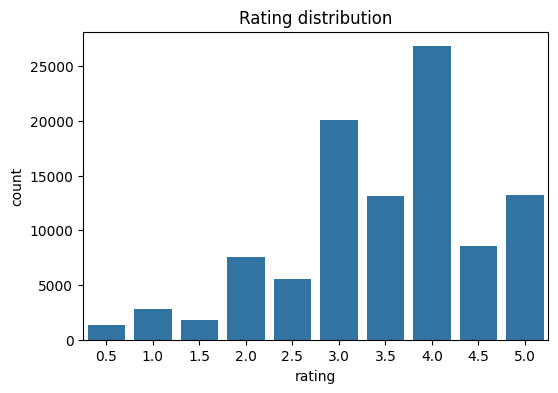

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(x="rating", data=ratings)
plt.title("Rating distribution")
plt.show()

In [25]:
data = ratings.merge(movies, on="movieId")

# sirf wo movies jinhein kam az kam 50 logon ne rate kiya
counts = data.groupby("title")["rating"].count()
popular = counts[counts >= 50].index
data = data[data["title"].isin(popular)]

matrix = data.pivot_table(index="userId", columns="title", values="rating").fillna(0)
print(matrix.shape)

(606, 450)


In [26]:
from sklearn.metrics.pairwise import cosine_similarity

sim = pd.DataFrame(cosine_similarity(matrix.T),
                   index=matrix.columns, columns=matrix.columns)

def recommend(title, n=5):
    return sim[title].sort_values(ascending=False).iloc[1:n + 1]

recommend("Toy Story (1995)")

,Toy Story (1995)
title,
Toy Story 2 (1999),0.572601
Jurassic Park (1993),0.565637
Independence Day (a.k.a. ID4) (1996),0.564262
Star Wars: Episode IV - A New Hope (1977),0.557388
Forrest Gump (1994),0.547096


In [27]:
import numpy as np

np.random.seed(42)
K = 10

# popularity baseline: sab se zyada rate hui movies
pop = data.groupby("title")["rating"].count().sort_values(ascending=False)

hit_rec, prec_rec, hit_pop, prec_pop = [], [], [], []

for user in matrix.index:
    row = matrix.loc[user]
    liked = row[row >= 4].index.tolist()
    if len(liked) < 5:
        continue

    # 20% pasandeeda movies test ke liye chhupa dein
    test = set(np.random.choice(liked, size=max(1, int(0.2 * len(liked))), replace=False))
    train_liked = [m for m in liked if m not in test]
    seen_train = [m for m in row[row > 0].index if m not in test]

    # our model: train movies se milti julti movies
    scores = sim[train_liked].sum(axis=1).drop(seen_train)
    top_rec = set(scores.nlargest(K).index)

    # baseline: popular movies
    top_pop = set(pop.drop(seen_train, errors="ignore").head(K).index)

    hit_rec.append(len(top_rec & test) > 0)
    prec_rec.append(len(top_rec & test) / K)
    hit_pop.append(len(top_pop & test) > 0)
    prec_pop.append(len(top_pop & test) / K)

print("Users evaluated:", len(prec_rec))
print(f"Our model  - Precision@{K}: {np.mean(prec_rec):.3f} | Hit rate@{K}: {np.mean(hit_rec):.3f}")
print(f"Popularity - Precision@{K}: {np.mean(prec_pop):.3f} | Hit rate@{K}: {np.mean(hit_pop):.3f}")

Users evaluated: 569
Our model  - Precision@10: 0.238 | Hit rate@10: 0.808
Popularity - Precision@10: 0.128 | Hit rate@10: 0.562
